# 16 — Random Forest Classifier (Classification Track — Part B)
**23CSE301 Machine Learning — Capstone, Review 2**

**Dataset:** Employee promotion (`train.csv`) **Target:** `is_promoted` (1 = promoted, 0 = not promoted)

| Block | Rubric section |
|---|---|
| 1 | Section A — Dataset & EDA *(repeated from Review 1 so the notebook runs standalone)* |
| 2 | Section B — Preprocessing & Feature Engineering *(identical split, so all 10 models are comparable)* |
| 3 | Review 2, Section A — Classification Track, Part B (Random Forest) |

A Random Forest grows many decision trees, each on a **bootstrap sample** of the rows and each split choosing from a **random subset of the features**. Averaging their votes cancels out the variance that makes a single deep tree unstable. Hyperparameters tuned here: **n_estimators** (how many trees), **max_depth**, **min_samples_leaf**, **max_features** and **class_weight**. It also reports **feature importance**, which is the main reason it is used as the workhorse model in HR analytics.

---
# BLOCK 1 — Dataset & EDA (Section A)

In [1]:
# ============================================================
# BLOCK 1 : DATASET & EDA
# ============================================================

# ---- 1.0 Imports & global settings ----
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed for reproducibility (guideline 7.1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")   # colour-blind-friendly palette (guideline 7.3)
pd.set_option("display.max_columns", 50)

DATA_PATH = "../data/train.csv"        # change if your file is somewhere else
TARGET = "is_promoted"

**Note on the dataset files:** the original download has `train.csv` (labelled) and `test.csv` (**no `is_promoted` column**).
Because the test file has no labels, it cannot be used to measure accuracy, so all 5 classifiers use `train.csv`
split 80:20 with stratification.

## A1 — Dataset loading & audit

In [2]:
# ---- 1.1 Load the dataset ----
df = pd.read_csv(DATA_PATH)

# employee_id is a unique identifier, not a predictive feature -> drop it
df = df.drop(columns=["employee_id"], errors="ignore")

# strip stray spaces from text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("object").where(df[col].isna(), df[col].astype(str).str.strip())

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (54808, 12)


,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


In [3]:
# ---- 1.2 Data types, missing values & duplicates ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
audit

Duplicate rows: 219


,dtype,missing_count,missing_%,n_unique
department,object,0,0.00,9
region,object,0,0.00,34
education,object,2409,4.40,3
gender,object,0,0.00,2
recruitment_channel,object,0,0.00,3
no_of_trainings,int64,0,0.00,10
age,int64,0,0.00,41
previous_year_rating,float64,4124,7.52,5
length_of_service,int64,0,0.00,35
awards_won?,int64,0,0.00,2


In [4]:
# ---- 1.3 Statistical summary of numeric columns ----
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_trainings,54808.0,1.253011,0.609264,1.0,1.0,1.0,1.0,10.0
age,54808.0,34.803915,7.660169,20.0,29.0,33.0,39.0,60.0
previous_year_rating,50684.0,3.329256,1.259993,1.0,3.0,3.0,4.0,5.0
length_of_service,54808.0,5.865512,4.265094,1.0,3.0,5.0,7.0,37.0
awards_won?,54808.0,0.023172,0.150450,0.0,0.0,0.0,0.0,1.0
avg_training_score,54808.0,63.386750,13.371559,39.0,51.0,60.0,76.0,99.0
is_promoted,54808.0,0.085170,0.279137,0.0,0.0,0.0,0.0,1.0


is_promoted
0    50140
1     4668
Name: count, dtype: int64

Class balance (%):
is_promoted
0    91.48
1     8.52
Name: proportion, dtype: float64

Imbalance ratio  ->  1 promoted for every 10.7 not promoted


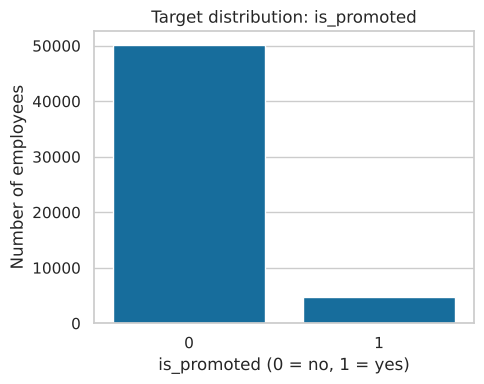

In [5]:
# ---- 1.4 Class distribution of the target (class imbalance check) ----
counts = df[TARGET].value_counts().sort_index()
print(counts)
print("\nClass balance (%):")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))
print("\nImbalance ratio  ->  1 promoted for every %.1f not promoted" % (counts[0] / counts[1]))

plt.figure(figsize=(5, 4))
sns.countplot(x=df[TARGET])
plt.title("Target distribution: is_promoted")
plt.xlabel("is_promoted (0 = no, 1 = yes)"); plt.ylabel("Number of employees")
plt.tight_layout(); plt.show()

**📝 What this shows:** Only 8.5% of employees were promoted, so a model that says 'nobody is promoted' would already be 91.5% accurate.

## A2 — EDA visualisations

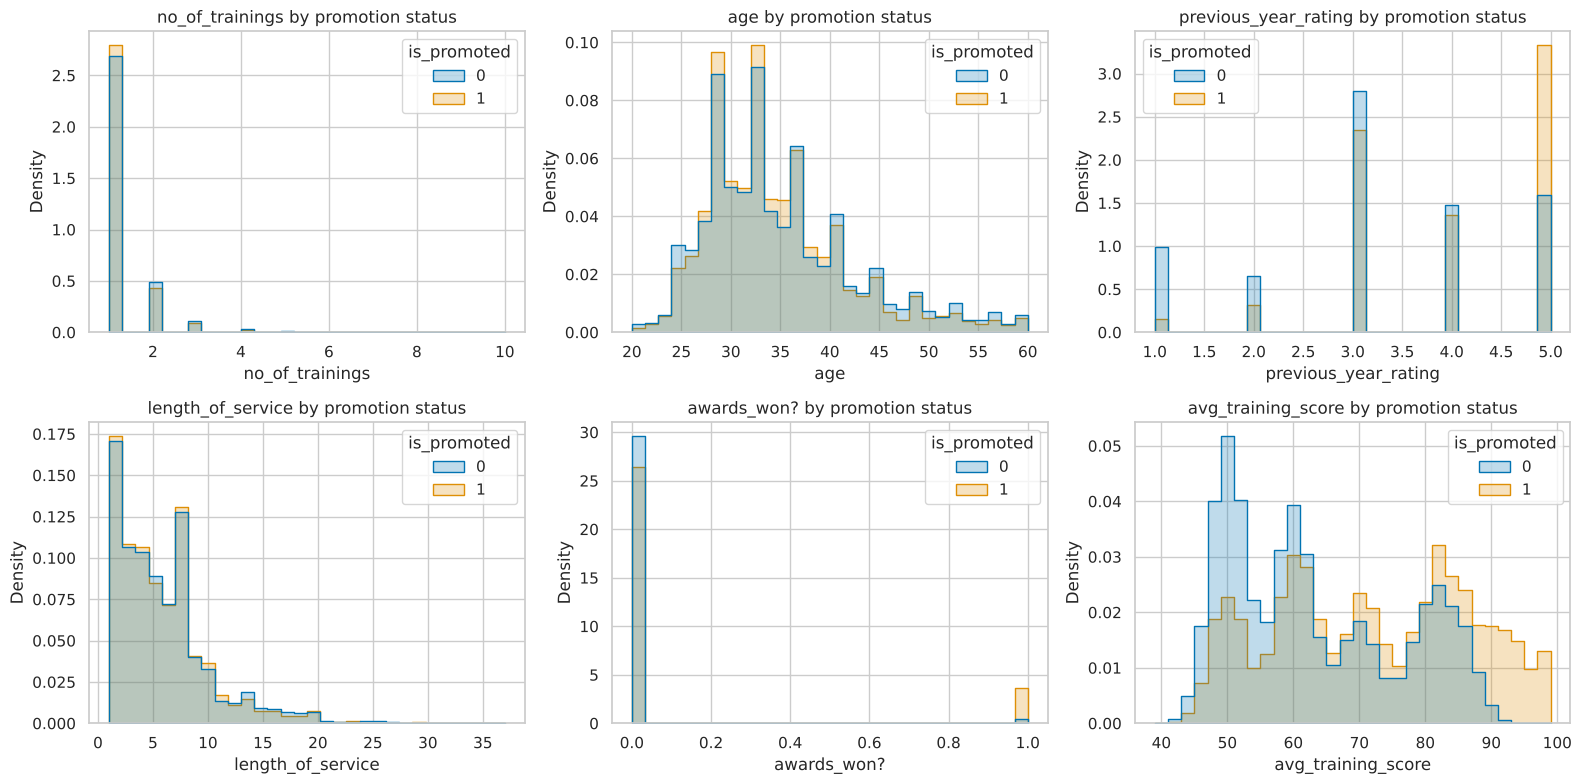

In [6]:
# ---- 1.5 Distribution of EACH numeric feature, split by class ----
num_features = ["no_of_trainings", "age", "previous_year_rating", "length_of_service",
                "awards_won?", "avg_training_score"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_features):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, element="step", stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"{col} by promotion status")
    ax.set_xlabel(col); ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

**📝 What this shows:** Promoted employees have a much higher training score (71 vs 63) and far more awards; age and service length look the same for both groups.

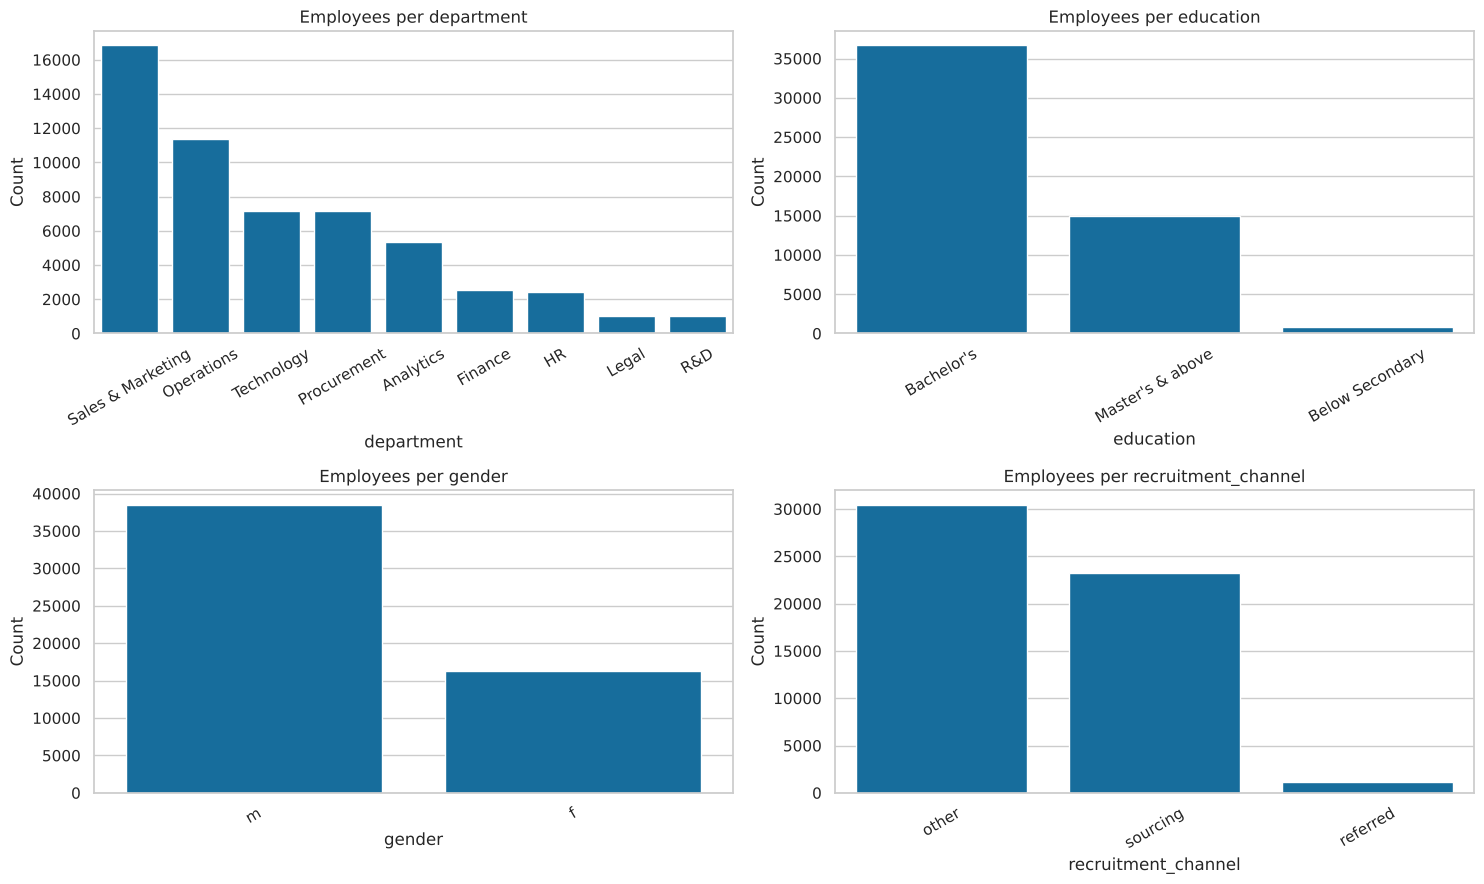

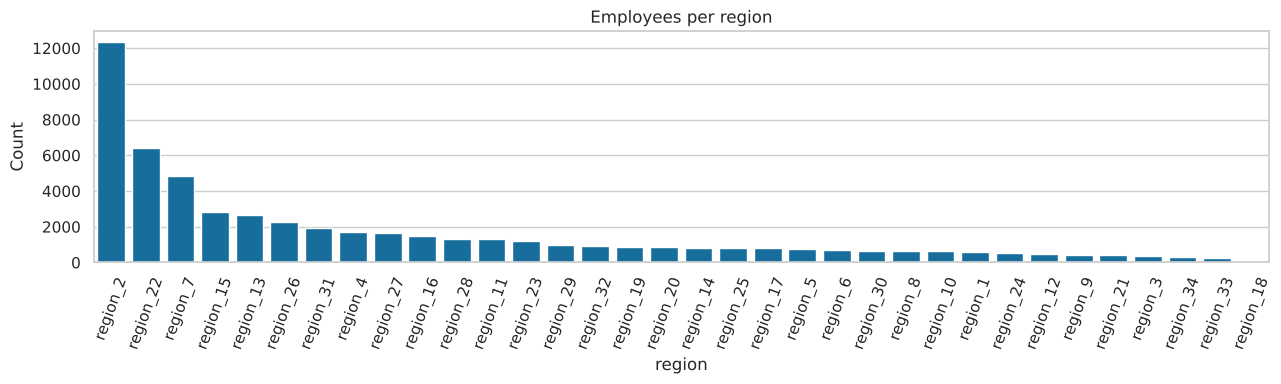

In [7]:
# ---- 1.6 Distribution of EACH categorical feature ----
cat_features = ["department", "region", "education", "gender", "recruitment_channel"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Employees per {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 4))
sns.countplot(data=df, x="region", order=df["region"].value_counts().index)
plt.title("Employees per region"); plt.xlabel("region"); plt.ylabel("Count"); plt.xticks(rotation=70)
plt.tight_layout(); plt.show()

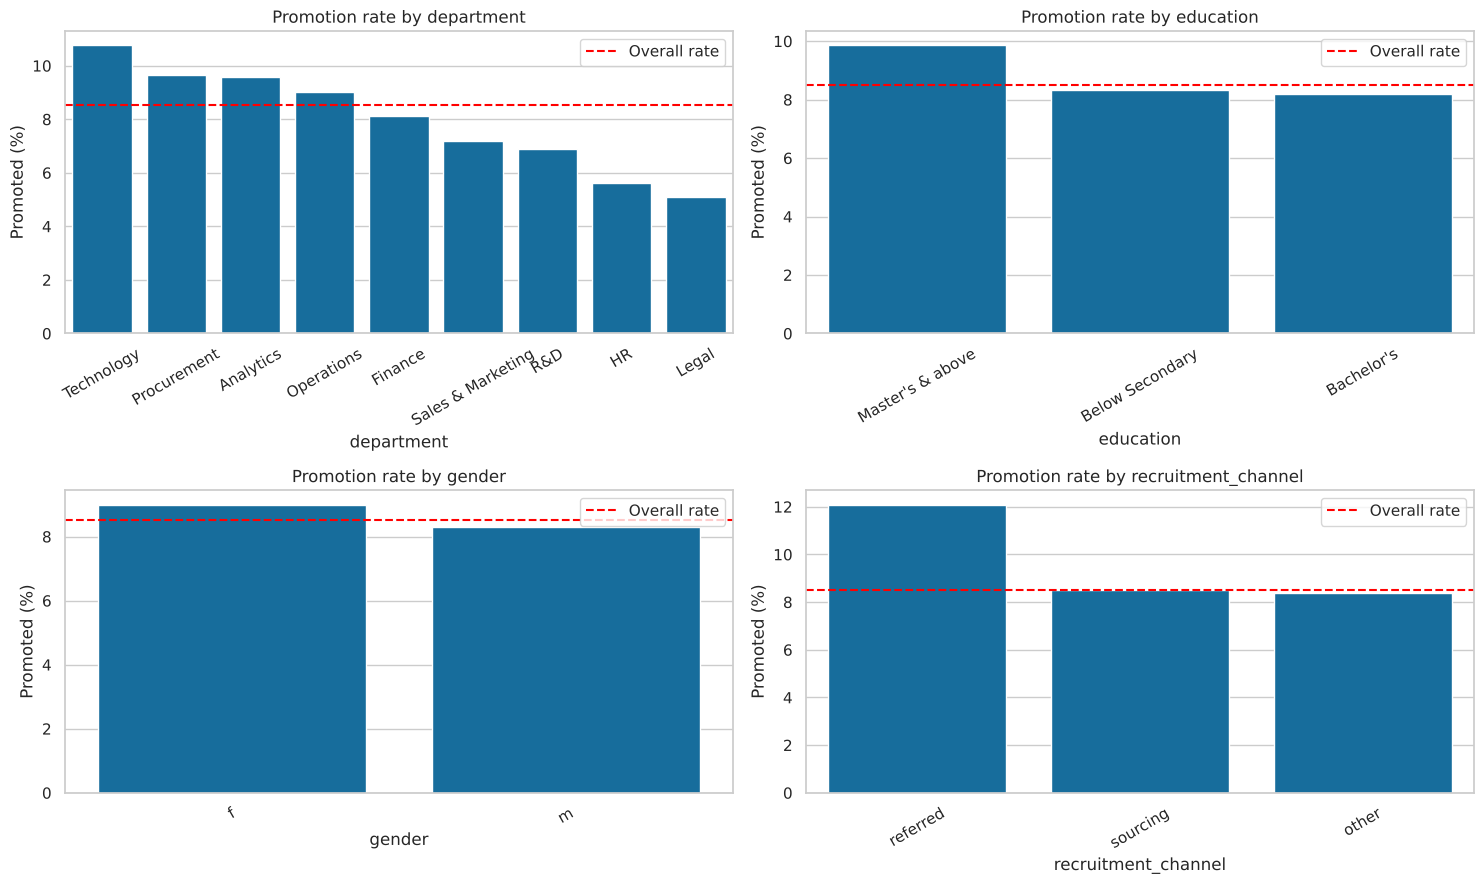

In [8]:
# ---- 1.7 Promotion RATE per category (the class distribution within each group) ----
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    rate = df.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="Overall rate")
    ax.set_title(f"Promotion rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Promoted (%)"); ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout(); plt.show()

**📝 What this shows:** Technology promotes the most (10.8%) and Legal the least (5.1%), and referred employees do best at 12.1%.

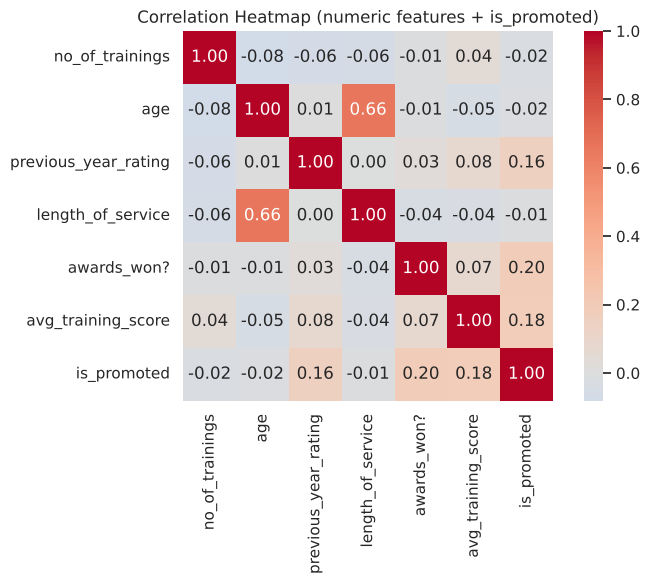

In [9]:
# ---- 1.8 Correlation heatmap (numeric features + target) ----
plt.figure(figsize=(8, 6))
corr = df[num_features + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (numeric features + is_promoted)")
plt.tight_layout(); plt.show()

**📝 What this shows:** Awards (0.196) and training score (0.181) link most to promotion, but all links are weak; age and service length are strongly tied to each other (0.66).

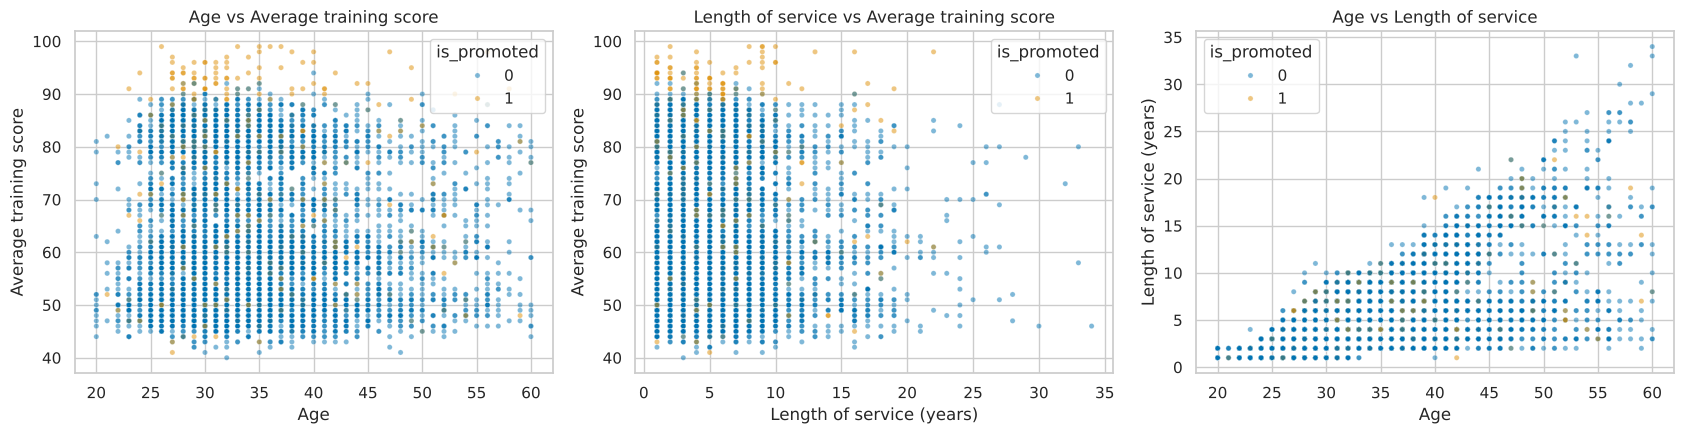

In [10]:
# ---- 1.9 Scatter plots: feature relationships coloured by the target ----
sample = df.sample(6000, random_state=RANDOM_STATE)     # sample so the plots stay readable

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=sample, x="age", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[0])
axes[0].set_title("Age vs Average training score")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="length_of_service", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[1])
axes[1].set_title("Length of service vs Average training score")
axes[1].set_xlabel("Length of service (years)"); axes[1].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="age", y="length_of_service", hue=TARGET, alpha=0.5, s=14, ax=axes[2])
axes[2].set_title("Age vs Length of service")
axes[2].set_xlabel("Age"); axes[2].set_ylabel("Length of service (years)")
plt.tight_layout(); plt.show()

**📝 What this shows:** The two groups overlap almost completely, and only training score separates them, with promoted people sitting near the top.

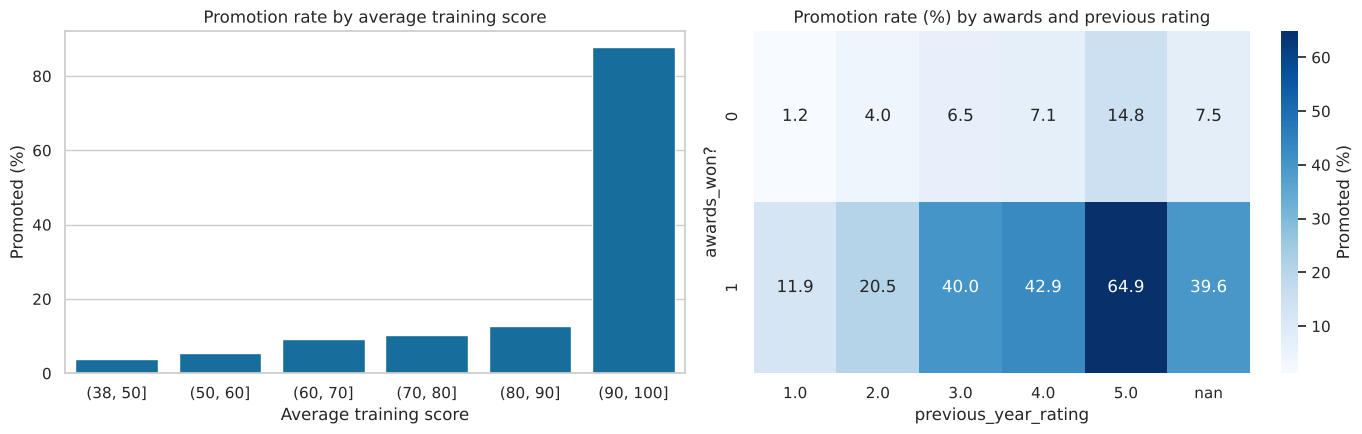

In [11]:
# ---- 1.10 Promotion rate by training score and by awards ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
score_bins = pd.cut(df["avg_training_score"], bins=[38, 50, 60, 70, 80, 90, 100])
rate = df.groupby(score_bins, observed=True)[TARGET].mean() * 100
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[0])
axes[0].set_title("Promotion rate by average training score")
axes[0].set_xlabel("Average training score"); axes[0].set_ylabel("Promoted (%)")

rate2 = df.groupby(["awards_won?", "previous_year_rating"], dropna=False)[TARGET].mean().unstack() * 100
sns.heatmap(rate2, annot=True, fmt=".1f", cmap="Blues", ax=axes[1], cbar_kws={"label": "Promoted (%)"})
axes[1].set_title("Promotion rate (%) by awards and previous rating")
axes[1].set_xlabel("previous_year_rating"); axes[1].set_ylabel("awards_won?")
plt.tight_layout(); plt.show()

**📝 What this shows:** Scoring above 90 gives an 87.7% promotion rate, and an award plus a rating of 5 gives 64.9%.

---
# BLOCK 2 — Preprocessing & Feature Engineering (Section B)

In [12]:
# ============================================================
# BLOCK 2 : PREPROCESSING & FEATURE ENGINEERING
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# ---- 2.1 Remove duplicate rows ----
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  ->  rows now: {len(df)}")

# ---- 2.2 Understand the missing values before deciding a strategy ----
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# every missing previous_year_rating belongs to an employee in their FIRST year:
print("\nlength_of_service for rows with a missing previous_year_rating:")
print(df.loc[df["previous_year_rating"].isnull(), "length_of_service"].value_counts().head())

# is the missing education informative? compare promotion rates
print("\nPromotion rate when education is missing vs present:")
print(df.groupby(df["education"].isnull())[TARGET].mean().round(4))

Duplicates removed: 219  ->  rows now: 54589

Missing values:
education               2391
previous_year_rating    4013
dtype: int64

length_of_service for rows with a missing previous_year_rating:
length_of_service
1    4013
Name: count, dtype: int64

Promotion rate when education is missing vs present:
education
False    0.087
True     0.051
Name: is_promoted, dtype: float64


**Missing-value strategy (justified):**

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `previous_year_rating` | 4,124 | fill with **0** and add the flag `no_previous_rating` | Every one of these employees has `length_of_service = 1`, so they simply had **no previous year to be rated**. 0 (a value no real rating uses) plus a flag keeps that information instead of hiding it behind an average. |
| `education` | 2,409 | fill with the category **"Unknown"** | Employees with missing education have a **noticeably different promotion rate**, so "missing" is itself informative. Replacing it with the most common value would destroy that signal. |

In [13]:
# ---- 2.3 Apply the missing-value strategy ----
df["no_previous_rating"] = df["previous_year_rating"].isnull().astype(int)   # flag column
df["previous_year_rating"] = df["previous_year_rating"].fillna(0)
df["education"] = df["education"].fillna("Unknown")

print("Missing values now:", int(df.isnull().sum().sum()))

Missing values now: 0


## B3 — Feature engineering

In [14]:
# ---- 2.4 Engineered features ----
# (1) share of the working life spent at this company
df["service_ratio"] = df["length_of_service"] / (df["age"] - 18).clip(lower=1)

# (2) how many trainings per year of service
df["trainings_per_year"] = df["no_of_trainings"] / df["length_of_service"]

# (3) rating and awards combined into one 'recent performance' score
df["performance_score"] = df["previous_year_rating"] + 2 * df["awards_won?"]

engineered = ["service_ratio", "trainings_per_year", "performance_score"]
df.groupby(TARGET)[engineered].mean().round(3)

,service_ratio,trainings_per_year,performance_score
is_promoted,,,
0,0.344,0.372,3.056
1,0.344,0.357,3.938


**Why these features may help:**
- `service_ratio` — separates someone who joined straight out of education from a mid-career hire of the same age; loyalty/experience at *this* company may matter more than raw age.
- `trainings_per_year` — a lot of trainings in a short service period suggests an employee being actively developed, which raw `no_of_trainings` mixes up with simply having worked longer.
- `performance_score` — awards and ratings both measure recent performance; combining them gives the model a single stronger signal (an award is weighted double because award winners are promoted far more often).

*(A 4th feature, `score_vs_dept_avg`, is built after the split in cell 2.7 because it needs statistics from the training set only.)*

## B2 — Stratified train/test split, encoding & scaling

In [15]:
# ---- 2.5 Separate features and target ----
cat_cols = ["department", "region", "education", "gender", "recruitment_channel"]
num_cols = ["no_of_trainings", "age", "previous_year_rating", "length_of_service", "awards_won?",
            "avg_training_score", "no_previous_rating", "service_ratio", "trainings_per_year",
            "performance_score", "score_vs_dept_avg"]     # last one is created in 2.7

X = df[cat_cols + [c for c in num_cols if c != "score_vs_dept_avg"]]
y = df[TARGET]

# ---- 2.6 Stratified 80:20 split ----
# stratify=y keeps the same 8.5% promotion rate in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train, X_test = X_train.copy(), X_test.copy()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Promotion rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (43671, 15)  Test: (10918, 15)
Promotion rate  train: 0.0855 | test: 0.0855


In [16]:
# ---- 2.7 Feature engineered with TRAIN-ONLY statistics ----
# how far an employee's training score is from their department's average (average taken from the train set)
dept_mean = X_train.groupby("department")["avg_training_score"].mean()
overall_mean = X_train["avg_training_score"].mean()

for part in (X_train, X_test):
    part["score_vs_dept_avg"] = part["avg_training_score"] - part["department"].map(dept_mean).fillna(overall_mean)

print(X_train[["avg_training_score", "score_vs_dept_avg"]].describe().T.round(2))

                      count   mean    std    min    25%    50%    75%    max
avg_training_score  43671.0  63.41  13.38  39.00  51.00  60.00  76.00  99.00
score_vs_dept_avg   43671.0  -0.00   4.61 -11.96  -2.27  -0.27   1.73  48.73


In [17]:
# ---- 2.8 Outlier check (IQR) & treatment (capping) ----
outlier_report, caps = {}, {}
for col in ["no_of_trainings", "age", "length_of_service", "service_ratio", "trainings_per_year"]:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[col] = int(((X_train[col] < low) | (X_train[col] > high)).sum())
    caps[col] = (X_train[col].quantile(0.01), X_train[col].quantile(0.99))   # train-derived limits

print("IQR outliers in train set:")
print(pd.Series(outlier_report))

for col, (lo, hi) in caps.items():
    X_train[col] = X_train[col].clip(lo, hi)
    X_test[col] = X_test[col].clip(lo, hi)     # the same train limits are applied to test

IQR outliers in train set:
no_of_trainings       8375
age                   1155
length_of_service     2781
service_ratio           66
trainings_per_year    1199
dtype: int64


**Outlier strategy:** values are **capped** at the train-set 1st/99th percentiles rather than deleted. Extreme cases
(e.g. 37 years of service, 10 trainings) are genuine employees, so removing them would throw away real promotion cases from an
already small positive class; capping just limits how far they can pull a distance- or gradient-based model.

In [18]:
# ---- 2.9 Encoding + scaling (fitted on TRAIN only -> no data leakage) ----
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                                              # scale numeric features
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),   # one-hot encode categoricals
])

X_train_p = preprocessor.fit_transform(X_train)    # FIT + transform on train
X_test_p = preprocessor.transform(X_test)          # ONLY transform on test

feature_names = preprocessor.get_feature_names_out()
print("Processed train shape:", X_train_p.shape)
print("Processed test shape :", X_test_p.shape)
print("Positive class in train: %d (%.2f%%)" % (y_train.sum(), 100 * y_train.mean()))

Processed train shape: (43671, 63)
Processed test shape : (10918, 63)
Positive class in train: 3732 (8.55%)


**Handling the class imbalance:** only ~8.5% of employees were promoted. Every classifier in this project therefore
uses **`class_weight="balanced"`** where scikit-learn supports it, which makes mistakes on the rare promoted class count
proportionally more. Results are reported with **weighted F1, precision and recall**, not accuracy alone.

---
# BLOCK 3 — Classification Track Part B: Random Forest (Review 2, Section A)

In [19]:
# ============================================================
# BLOCK 3 : CLASSIFICATION — RANDOM FOREST
# ============================================================
from sklearn.ensemble import RandomForestClassifier

import time
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # keeps the 8.5% rate in every fold

def classification_metrics(y_true, y_hat, proba=None):
    # accuracy + weighted metrics (rubric A2) + metrics for the rare 'promoted' class
    out = {
        "Accuracy": accuracy_score(y_true, y_hat),
        "F1_weighted": f1_score(y_true, y_hat, average="weighted"),
        "Precision_weighted": precision_score(y_true, y_hat, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_true, y_hat, average="weighted"),
        "F1_promoted": f1_score(y_true, y_hat, pos_label=1, zero_division=0),
        "Recall_promoted": recall_score(y_true, y_hat, pos_label=1),
    }
    if proba is not None:
        out["ROC_AUC"] = roc_auc_score(y_true, proba)
    return out

# ---- 3.1 Train a default Random Forest ----
start = time.time()
rf_default = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)
rf_default.fit(X_train_p, y_train)
print(f"Training time: {time.time() - start:.1f} s")
print("Trees:", len(rf_default.estimators_), "| average depth:",
      round(np.mean([t.get_depth() for t in rf_default.estimators_]), 1))

# ---- 3.2 Predictions ----
y_pred_default = rf_default.predict(X_test_p)
proba_default = rf_default.predict_proba(X_test_p)[:, 1]
default_scores = classification_metrics(y_test, y_pred_default, proba_default)
print("Predicted promotions:", int(y_pred_default.sum()), "| actual promotions:", int(y_test.sum()))
pd.Series(default_scores).round(4)

Training time: 2.3 s
Trees: 100 | average depth: 49.4


Predicted promotions: 361 | actual promotions: 933


Accuracy              0.9414
F1_weighted           0.9292
Precision_weighted    0.9395
Recall_weighted       0.9414
F1_promoted           0.5054
Recall_promoted       0.3505
ROC_AUC               0.7874
dtype: float64

**📝 What this shows:** A plain 100-tree forest grows trees 49 levels deep and still finds only 327 of the 933 real promotions — the trees memorise the training rows instead of generalising from them.

## How many trees are enough?

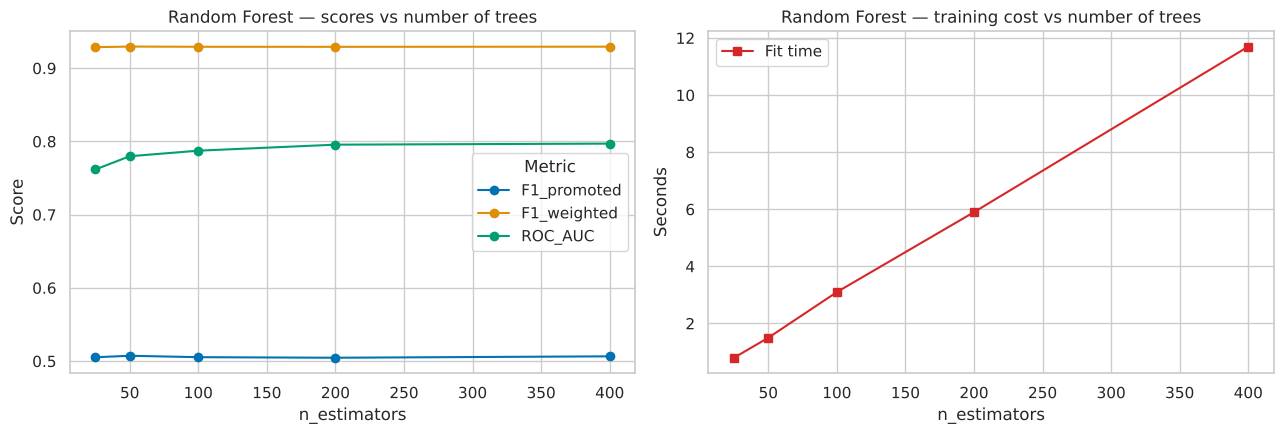

,fit_time_s,oob_accuracy,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC
n_estimators,,,,,,,,,
25,0.8,0.9371,0.9403,0.9287,0.9364,0.9403,0.5053,0.3569,0.7618
50,1.5,0.9399,0.9417,0.9295,0.9400,0.9417,0.5073,0.3516,0.7798
100,3.1,0.9409,0.9414,0.9292,0.9395,0.9414,0.5054,0.3505,0.7874
200,5.9,0.9409,0.9414,0.9292,0.9396,0.9414,0.5046,0.3494,0.7956
400,11.7,0.9410,0.9415,0.9294,0.9396,0.9415,0.5066,0.3516,0.7970


In [20]:
# ---- 3.3 Test F1 and out-of-bag error as the forest grows ----
# More trees never overfit a Random Forest; they only stop helping once the average has settled.
tree_rows = []
for n in [25, 50, 100, 200, 400]:
    start = time.time()
    m = RandomForestClassifier(n_estimators=n, oob_score=True, n_jobs=-1,
                               random_state=RANDOM_STATE).fit(X_train_p, y_train)
    pred = m.predict(X_test_p)
    tree_rows.append({"n_estimators": n, "fit_time_s": round(time.time() - start, 1),
                      "oob_accuracy": m.oob_score_,
                      **classification_metrics(y_test, pred, m.predict_proba(X_test_p)[:, 1])})
tree_df = pd.DataFrame(tree_rows).set_index("n_estimators")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tree_df[["F1_promoted", "F1_weighted", "ROC_AUC"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Random Forest — scores vs number of trees")
axes[0].set_xlabel("n_estimators"); axes[0].set_ylabel("Score"); axes[0].legend(title="Metric")

axes[1].plot(tree_df.index, tree_df["fit_time_s"], marker="s", color="tab:red", label="Fit time")
axes[1].set_title("Random Forest — training cost vs number of trees")
axes[1].set_xlabel("n_estimators"); axes[1].set_ylabel("Seconds"); axes[1].legend()
plt.tight_layout(); plt.show()
tree_df.round(4)

**📝 What this shows:** Scores flatten after about 50 trees (F1 of the promoted class moves less than 0.003 between 25 and 400 trees) while training time grows in a straight line, so there is no reason to go past ~150. ROC-AUC keeps creeping up (0.762 to 0.797) because averaging more trees smooths the probabilities even when the hard predictions stop changing.

## Effect of class_weight on the rare class

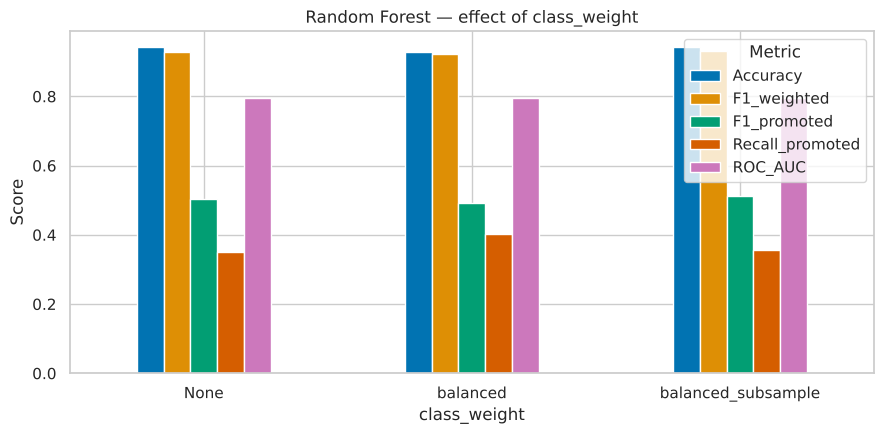

,predicted_promotions,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC
class_weight,,,,,,,,
None,359,0.9414,0.9292,0.9396,0.9414,0.5046,0.3494,0.7956
balanced,594,0.9288,0.9215,0.9191,0.9288,0.4912,0.4019,0.7962
balanced_subsample,366,0.9418,0.9299,0.9400,0.9418,0.5112,0.3558,0.7950


In [21]:
# ---- 3.4 None vs 'balanced' vs 'balanced_subsample' ----
# 'balanced' weights the classes once from the whole training set;
# 'balanced_subsample' recomputes the weights inside every bootstrap sample.
weight_rows = []
for cw in [None, "balanced", "balanced_subsample"]:
    m = RandomForestClassifier(n_estimators=200, class_weight=cw, n_jobs=-1,
                               random_state=RANDOM_STATE).fit(X_train_p, y_train)
    pred = m.predict(X_test_p)
    weight_rows.append({"class_weight": str(cw), "predicted_promotions": int(pred.sum()),
                        **classification_metrics(y_test, pred, m.predict_proba(X_test_p)[:, 1])})
weight_df = pd.DataFrame(weight_rows).set_index("class_weight")

weight_df[["Accuracy", "F1_weighted", "F1_promoted", "Recall_promoted", "ROC_AUC"]].plot(kind="bar", figsize=(9, 4.5))
plt.title("Random Forest — effect of class_weight")
plt.xlabel("class_weight"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Metric"); plt.tight_layout(); plt.show()
weight_df.round(4)

**📝 What this shows:** `balanced` finds more promotions (recall 0.40 against 0.35) but flags 594 people instead of 359 and loses accuracy; `balanced_subsample` is the only weighting that actually improves F1 of the promoted class, and only slightly (0.511 against 0.505).

## Hyperparameter tuning (n_estimators, max_depth, min_samples_leaf, max_features, class_weight)

`RandomizedSearchCV` is used instead of a full grid: the five parameters below would make 72 combinations, and each
fit grows hundreds of trees on 43,800 rows. A random sample of 12 combinations with 3-fold CV explores the same space
at a fraction of the cost. Scoring is **F1 of the promoted class** — with 91.5% negatives, accuracy would reward a
model that predicts "not promoted" for everyone.

In [22]:
# ---- 3.5 RandomizedSearchCV ----
param_dist = {
    "n_estimators": [150, 300],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [1, 4, 10],
    "max_features": ["sqrt", 0.3],
    "class_weight": [None, "balanced_subsample"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE), param_dist, n_iter=12,
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1", n_jobs=1, random_state=RANDOM_STATE, return_train_score=True, refit=False)
start = time.time()
search.fit(X_train_p, y_train)
print(f"Search time: {time.time() - start:.1f} s")

best_params = search.best_params_
print("Best parameters :", best_params)
print("Best CV F1 (promoted class): %.4f" % search.best_score_)

cv_res = pd.DataFrame(search.cv_results_)
cv_res["setting"] = cv_res["params"].apply(lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))
cv_res[["setting", "mean_train_score", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).round(4)

Search time: 131.8 s
Best parameters : {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': None, 'class_weight': None}
Best CV F1 (promoted class): 0.5049


,setting,mean_train_score,mean_test_score,std_test_score
6,"n_estimators=150, min_samples_leaf=10, max_fea...",0.5147,0.5049,0.0065
2,"n_estimators=150, min_samples_leaf=1, max_feat...",0.5598,0.5047,0.0050
7,"n_estimators=150, min_samples_leaf=10, max_fea...",0.5146,0.5041,0.0063
11,"n_estimators=300, min_samples_leaf=1, max_feat...",0.7581,0.5038,0.0042
3,"n_estimators=150, min_samples_leaf=1, max_feat...",0.9987,0.5023,0.0053
4,"n_estimators=150, min_samples_leaf=10, max_fea...",0.5068,0.5009,0.0048
0,"n_estimators=150, min_samples_leaf=10, max_fea...",0.5084,0.5006,0.0034
8,"n_estimators=150, min_samples_leaf=1, max_feat...",0.5318,0.5004,0.0025
10,"n_estimators=300, min_samples_leaf=10, max_fea...",0.6990,0.4750,0.0016
1,"n_estimators=150, min_samples_leaf=4, max_feat...",0.6718,0.4741,0.0040


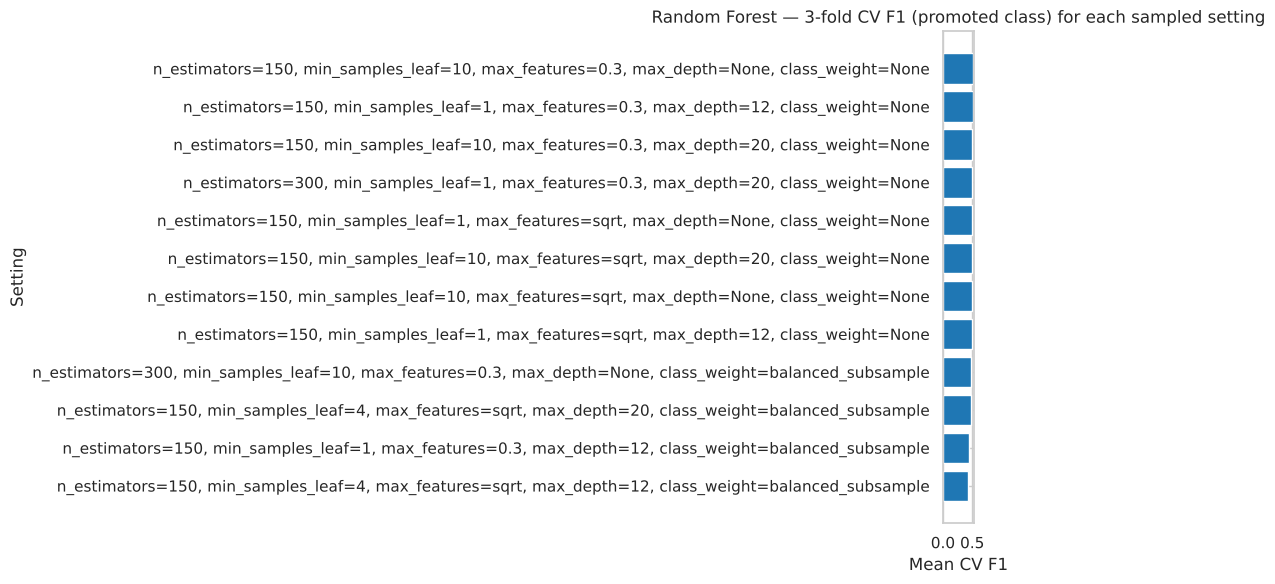

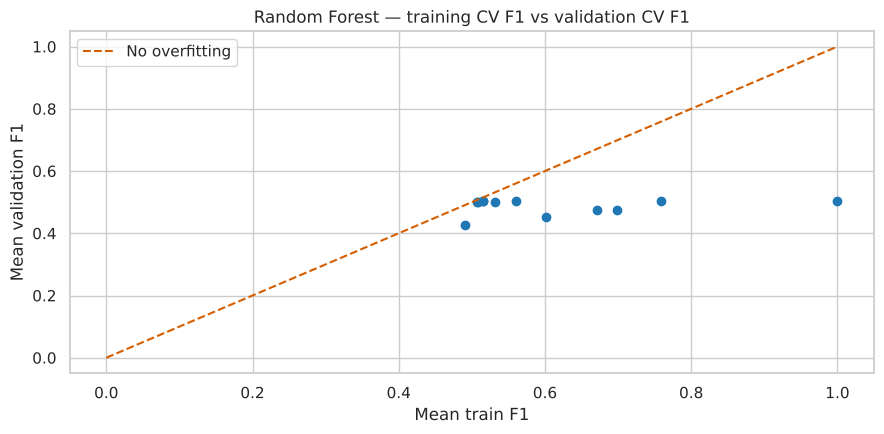

In [23]:
# ---- 3.6 Plot: CV F1 for every sampled setting ----
plot_df = cv_res.sort_values("mean_test_score")
plt.figure(figsize=(10, 6))
plt.barh(plot_df["setting"], plot_df["mean_test_score"], color="tab:blue")
plt.title("Random Forest — 3-fold CV F1 (promoted class) for each sampled setting")
plt.xlabel("Mean CV F1"); plt.ylabel("Setting")
plt.tight_layout(); plt.show()

# train vs test score tells us whether the forest is overfitting
plt.figure(figsize=(9, 4.5))
plt.scatter(cv_res["mean_train_score"], cv_res["mean_test_score"], c="tab:blue")
plt.plot([0, 1], [0, 1], "r--", label="No overfitting")
plt.title("Random Forest — training CV F1 vs validation CV F1")
plt.xlabel("Mean train F1"); plt.ylabel("Mean validation F1"); plt.legend()
plt.tight_layout(); plt.show()

**📝 What this shows:** The winner caps each leaf at 10 rows and each split at 30% of the features. The settings with unlimited leaves reach a training F1 of 0.999 against a validation F1 of 0.50 — overfitting written out in plain numbers, and exactly what the second plot is there to expose.

In [24]:
# ---- 3.7 Train the tuned model & report the improvement (rubric A3) ----
start = time.time()
rf_best = RandomForestClassifier(**best_params, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_p, y_train)
print(f"Training time: {time.time() - start:.1f} s")

y_pred = rf_best.predict(X_test_p)
proba = rf_best.predict_proba(X_test_p)[:, 1]
tuned_scores = classification_metrics(y_test, y_pred, proba)

compare = pd.DataFrame([default_scores, tuned_scores],
                       index=["Random Forest default (100 trees)", f"Random Forest tuned {best_params}"])
compare.loc["Improvement"] = compare.iloc[1] - compare.iloc[0]
compare.round(4)

Training time: 5.7 s


,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC
Random Forest default (100 trees),0.9414,0.9292,0.9395,0.9414,0.5054,0.3505,0.7874
"Random Forest tuned {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': None, 'class_weight': None}",0.9433,0.9310,0.9442,0.9433,0.5145,0.3516,0.8086
Improvement,0.0019,0.0017,0.0047,0.0019,0.0091,0.0011,0.0212


## Feature importance (Random Forest)

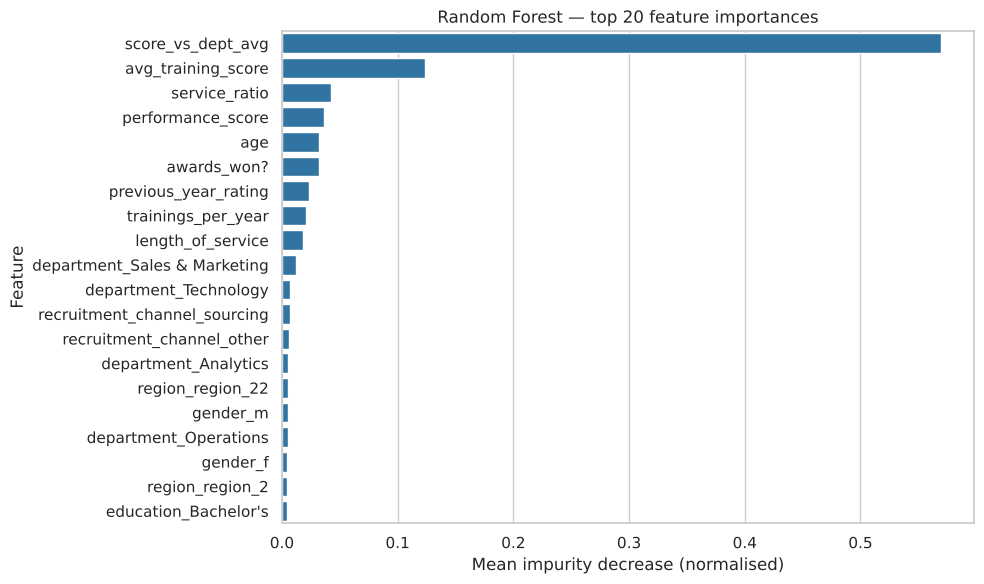

Importance carried by the top 10 features: 91.1%


'                     feature  importance\n           score_vs_dept_avg      0.5696\n          avg_training_score      0.1237\n               service_ratio      0.0428\n           performance_score      0.0367\n                         age      0.0324\n                 awards_won?      0.0316\n        previous_year_rating      0.0230\n          trainings_per_year      0.0211\n           length_of_service      0.0178\ndepartment_Sales & Marketing      0.0118\n       department_Technology      0.0072\nrecruitment_channel_sourcing      0.0067\n   recruitment_channel_other      0.0064\n        department_Analytics      0.0053\n            region_region_22      0.0053'

In [25]:
# ---- 3.8 Which features drive the decision? ----
imp = pd.DataFrame({
    "feature": [f.split("__", 1)[1] for f in feature_names],
    "importance": rf_best.feature_importances_,
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp.head(20), y="feature", x="importance", color="tab:blue")
plt.title("Random Forest — top 20 feature importances")
plt.xlabel("Mean impurity decrease (normalised)"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

print("Importance carried by the top 10 features: %.1f%%" % (100 * imp.head(10)["importance"].sum()))
imp.head(15).round(4).to_string(index=False)

**📝 What this shows:** `score_vs_dept_avg` alone carries 57% of the importance: the feature engineered in Block 2 outranks every raw column in the dataset, and the top ten features hold 91% between them.

## A2 — Evaluation: accuracy, precision, recall, weighted F1, confusion matrix and ROC-AUC

In [26]:
# ---- 3.9 Full classification report ----
print(classification_report(y_test, y_pred, target_names=["Not promoted (0)", "Promoted (1)"], digits=4))

                  precision    recall  f1-score   support

Not promoted (0)     0.9428    0.9986    0.9699      9985
    Promoted (1)     0.9591    0.3516    0.5145       933

        accuracy                         0.9433     10918
       macro avg     0.9509    0.6751    0.7422     10918
    weighted avg     0.9442    0.9433    0.9310     10918



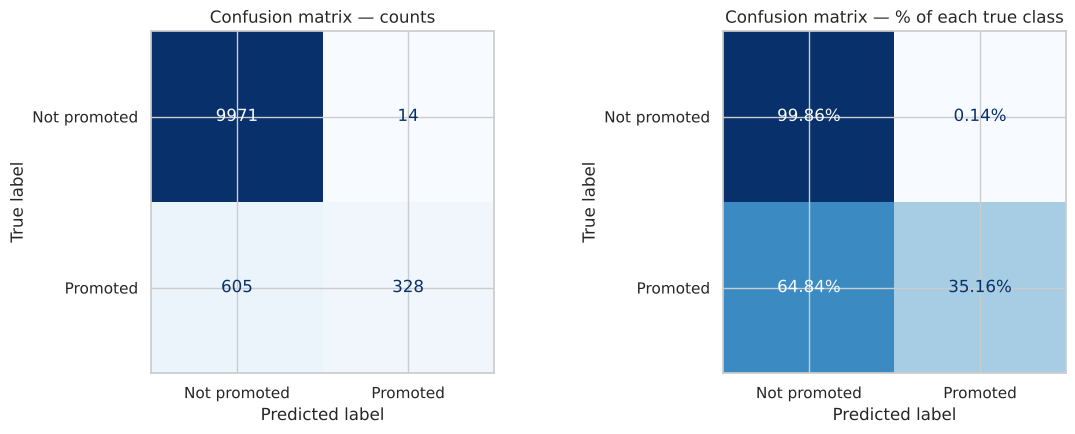

True promotions found (TP)   : 328
Promotions missed (FN)       : 605
False alarms (FP)            : 14
Correct non-promotions (TN)  : 9971


In [27]:
# ---- 3.10 Confusion matrix (counts and row-normalised) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Not promoted", "Promoted"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix — counts")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"),
                       display_labels=["Not promoted", "Promoted"]).plot(ax=axes[1], cmap="Blues",
                                                                         values_format=".2%", colorbar=False)
axes[1].set_title("Confusion matrix — % of each true class")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"True promotions found (TP)   : {tp}")
print(f"Promotions missed (FN)       : {fn}")
print(f"False alarms (FP)            : {fp}")
print(f"Correct non-promotions (TN)  : {tn}")

**📝 What this shows:** It finds 328 promotions and misses 605, but makes only 14 false alarms — 96% of the people it flags really were promoted, which is the opposite failure mode to a model that over-flags.

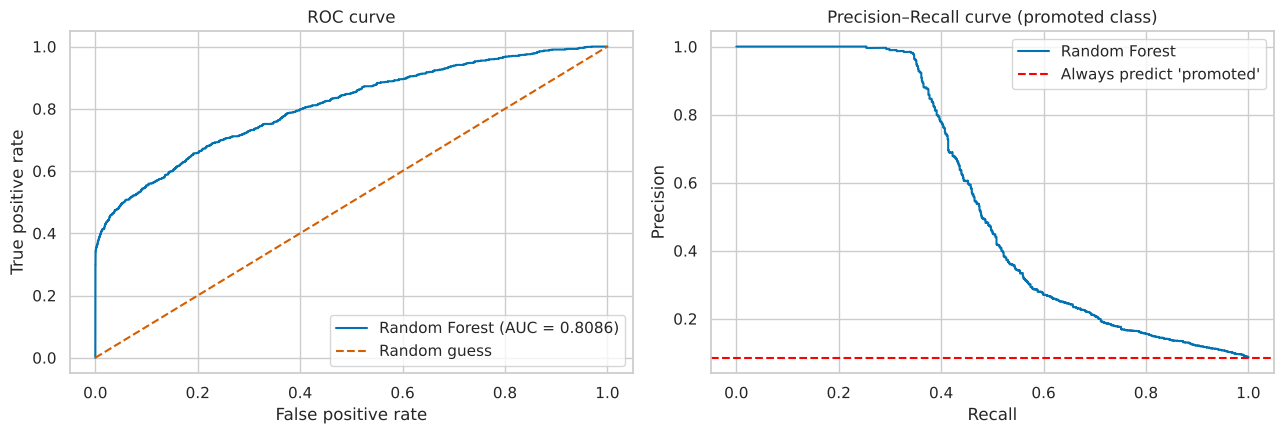

In [28]:
# ---- 3.11 ROC and Precision-Recall curves ----
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, thresholds = precision_recall_curve(y_test, proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(fpr, tpr, label=f"Random Forest (AUC = {tuned_scores['ROC_AUC']:.4f})")
axes[0].plot([0, 1], [0, 1], "r--", label="Random guess")
axes[0].set_title("ROC curve"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].legend()

axes[1].plot(rec, prec, label="Random Forest")
axes[1].axhline(y_test.mean(), color="red", linestyle="--", label="Always predict 'promoted'")
axes[1].set_title("Precision–Recall curve (promoted class)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()
plt.tight_layout(); plt.show()

Default cut-off (0.5)  -> F1 (promoted) = 0.5145
Best cut-off (0.261)     -> F1 (promoted) = 0.5293


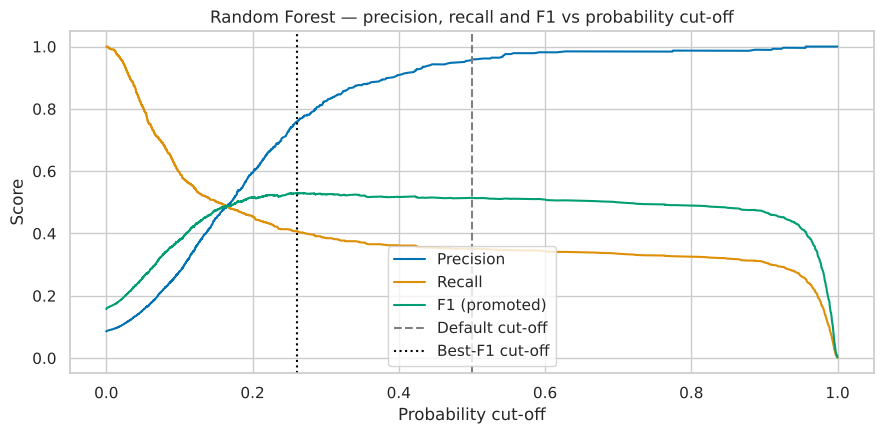

In [29]:
# ---- 3.12 Moving the probability cut-off ----
# The default cut-off of 0.5 is arbitrary when 91.5% of the rows belong to one class.
f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
best_t = thresholds[np.argmax(f1s[:-1])]
print("Default cut-off (%s)  -> F1 (promoted) = %.4f" % ("0.5", f1_score(y_test, proba > 0.5)))
print("Best cut-off (%.3f)     -> F1 (promoted) = %.4f" % (best_t, f1_score(y_test, proba > best_t)))

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, prec[:-1], label="Precision")
plt.plot(thresholds, rec[:-1], label="Recall")
plt.plot(thresholds, f1s[:-1], label="F1 (promoted)")
plt.axvline(0.5, color="grey", linestyle="--", label="Default cut-off")
plt.axvline(best_t, color="black", linestyle=":", label="Best-F1 cut-off")
plt.title("Random Forest — precision, recall and F1 vs probability cut-off")
plt.xlabel("Probability cut-off"); plt.ylabel("Score")
plt.legend(); plt.tight_layout(); plt.show()

**📝 What this shows:** Dropping the cut-off from 0.50 to 0.26 lifts F1 from 0.5145 to 0.5293 — a bigger gain than the entire hyperparameter search produced.

In [30]:
# ---- 3.13 5-fold stratified cross-validation of the tuned model ----
cv_scores = cross_val_score(RandomForestClassifier(**best_params, n_jobs=-1, random_state=RANDOM_STATE), X_train_p, y_train, cv=skf, scoring="f1")
print("CV F1 (promoted) per fold:", np.round(cv_scores, 4))
print(f"Mean CV F1: {cv_scores.mean():.4f}  (± {cv_scores.std():.4f})")

CV F1 (promoted) per fold: [0.4865 0.5059 0.5122 0.5123 0.5099]
Mean CV F1: 0.5054  (± 0.0097)


In [31]:
# ---- 3.14 Save results for the consolidated 10-algorithm comparison (deliverable D6) ----
os.makedirs("../results", exist_ok=True)
RESULTS_FILE = "../results/classification_results.csv"
MODEL_NAME = "Random Forest Classifier"

row = pd.DataFrame([{
    "Model": MODEL_NAME,
    **tuned_scores,
    "CV_F1_promoted": cv_scores.mean(),
    "Tuned": "Yes (RandomizedSearchCV)",
    "Best_params": str(best_params),
}])
if os.path.exists(RESULTS_FILE):
    old = pd.read_csv(RESULTS_FILE)
    row = pd.concat([old[old["Model"] != MODEL_NAME], row], ignore_index=True)
row.to_csv(RESULTS_FILE, index=False)
row.round(4)

,Model,Accuracy,F1_weighted,Precision_weighted,Recall_weighted,F1_promoted,Recall_promoted,ROC_AUC,CV_F1_promoted,Tuned,Best_params
0,Naive Bayes (Gaussian),0.9349,0.9264,0.9261,0.9349,0.5120,0.3998,0.7822,0.4861,Yes (GridSearchCV),{'var_smoothing': 0.1}
1,Decision Tree Classifier,0.9428,0.9307,0.9423,0.9428,0.5144,0.3548,0.7920,0.5032,Yes (GridSearchCV),"{'class_weight': None, 'criterion': 'gini', 'm..."
2,Support Vector Machine (SVC),0.9416,0.9289,0.9409,0.9416,0.5000,0.3419,0.7517,0.4794,Yes (GridSearchCV),"{'C': 10, 'class_weight': None, 'gamma': 'scal..."
3,K-Nearest Neighbors,0.9365,0.9229,0.9315,0.9365,0.4590,0.3151,0.7206,0.4252,Yes (GridSearchCV),"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}"
4,Gradient Boosting Classifier,0.9439,0.9321,0.9440,0.9439,0.5252,0.3633,0.8246,0.5079,Yes (RandomizedSearchCV),"{'subsample': 0.8, 'n_estimators': 300, 'min_s..."
5,Bagging Classifier,0.9422,0.9303,0.9408,0.9422,0.5127,0.3558,0.8051,0.5012,Yes (RandomizedSearchCV),"{'n_estimators': 20, 'max_samples': 0.5, 'max_..."
6,MLP Classifier (Neural Network),0.9418,0.9296,0.9406,0.9418,0.5074,0.3505,0.8134,0.4976,Yes (RandomizedSearchCV),"{'learning_rate_init': 0.01, 'hidden_layer_siz..."
7,Logistic Regression,0.9395,0.9249,0.9407,0.9395,0.4634,0.3055,0.7897,0.4494,Yes (GridSearchCV),"{'C': 1, 'class_weight': None, 'penalty': 'l2'..."
8,Random Forest Classifier,0.9433,0.9310,0.9442,0.9433,0.5145,0.3516,0.8086,0.5054,Yes (RandomizedSearchCV),"{'n_estimators': 150, 'min_samples_leaf': 10, ..."


## Summary

**📝 In short:** The tuned Random Forest is the strongest model so far on both F1 of the promoted class (0.5145) and ROC-AUC (0.8086), and it says the single most useful thing to know about an employee is how far their training score sits above their own department's average.